# 05 — Perbandingan Validasi Kandidat Segmentasi EBHI-SEG

## Ringkasan utama

Notebook ini mengonsolidasikan **hasil validasi yang telah disimpan** menjadi analisis terverifikasi atas **13 metode**, **372 citra validasi**, **enam kategori diagnostik**, dan **empat visualisasi utama**.

Pada checkpoint `8192e3e09384b05fa760104436f3a2e226380ac3`, kandidat *image-dependent* terbaik adalah **K-means Lab `k=4, M0`** dengan *equal-category mean* Dice **0.7761** (`IoU = 0.6427`), sedangkan kontrol konstan **`all_foreground`** mencapai **0.7767** (`IoU = 0.6477`). Hasil ini bersifat deskriptif pada `val`; belum membuktikan keunggulan atas kontrol maupun manfaat bagi klasifikasi hilir.

## Konteks dan kontrak metodologi

**Pertanyaan:** kandidat segmentasi global mana yang memiliki tumpang tindih *foreground* validasi tertinggi, dan bagaimana posisinya terhadap kontrol konstan yang memprediksi seluruh piksel sebagai *foreground*?

### Aturan ilmiah yang dipertahankan

- `split_manifest.csv` menjadi otoritas kohort (`372` citra `val`). `group_id` berbasis prefix nama file adalah kunci pengelompokan sementara, bukan ID pasien terverifikasi.
- Polaritas Otsu (`dark`), pusat *cluster* Lab, dan pemetaan *foreground* (`rate >= 0.5`) seluruhnya dipelajari pada subset `train`.
- Referensi biner menggunakan `mask >= 128`.
- **M0:** *mask* mentah. **M1:** mempertahankan komponen *8-connected* berukuran minimal 16 piksel. **M2:** M1 diikuti *opening* lalu *closing* dengan kernel silang `3×3`, masing-masing satu iterasi, `BORDER_REPLICATE`.
- **Metrik utama:** rerata skor citra di dalam tiap kategori terlebih dahulu, kemudian rerata bobot sama lintas enam kategori.
- **Aturan seleksi kandidat:** Dice dibulatkan empat desimal, lalu IoU empat desimal, lalu tahap morfologi lebih sedikit, lalu jumlah *cluster* lebih kecil. Perhitungan internal tetap memakai presisi penuh `float64`.

**Batas eksekusi:** hanya membaca artefak CSV/JSON yang tersimpan; tidak melatih ulang model, tidak mengubah *split*, dan tidak mengevaluasi `test`.

In [1]:
%matplotlib inline

import json
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ebhi_dip import (
    EXPECTED_CATEGORIES,
    STAGES,
    category_score_table,
    configure_notebook_style,
    find_project_root,
    finish_figure,
    load_split_manifest,
    load_validation_results,
    method_label,
    selection_ranking_key,
    sha256_bytes,
    summarize_validation_methods,
    verify_frozen_split,
    verify_helper_provenance,
)

PROJECT_ROOT_OVERRIDE = None
EXPORT_FIGURES = False

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
configure_notebook_style()

display(
    pd.DataFrame(
        {
            "komponen": ["Python", "NumPy", "pandas", "Matplotlib"],
            "versi_runtime_analisis": [
                platform.python_version(),
                np.__version__,
                pd.__version__,
                matplotlib.__version__,
            ],
        }
    )
)

,komponen,versi_runtime_analisis
0,Python,3.14.0
1,NumPy,2.5.4
2,pandas,3.1.1
3,Matplotlib,3.11.2


## 1. Memuat kohort validasi dan rekonsiliasi tabel skor

`load_validation_results(ROOT)` memvalidasi *checksum* *frozen split*, provenance ketiga model JSON dan metadata *run*, menyelaraskan skema lebar `otsu_morph_val.csv` dengan skema panjang `kmeans_morph_val.csv`, serta memverifikasi bahwa kontrol `all_foreground` pada kedua sumber cocok per citra dan memenuhi identitas analitik $\mathrm{Dice} = 2r/(1+r)$ serta $\mathrm{IoU} = r$ untuk fraksi cakupan referensi $r$.

In [2]:
source_files = {
    "split": ROOT / "data/metadata/split_manifest.csv",
    "split_checksum": ROOT / "data/metadata/split_manifest.sha256",
    "otsu": ROOT / "results/otsu_morph_val.csv",
    "kmeans": ROOT / "results/kmeans_morph_val.csv",
    "run": ROOT / "results/kmeans_morph_val_run.json",
    "otsu_config": ROOT / "configs/otsu_raw.json",
    "provenance_migration": ROOT / "configs/provenance_migration.json",
}
source_files.update({f"model_k{k}": ROOT / f"models/kmeans_lab_k{k}_mapped.json" for k in (2, 3, 4)})
input_hashes_before = {name: sha256_bytes(path) for name, path in source_files.items()}

split_df = load_split_manifest(ROOT, verify=False)
validation = split_df.loc[split_df["split"].eq("val")].copy()
results = load_validation_results(ROOT)

cohort_table = (
    validation.groupby("category", observed=True)
    .agg(validation_images=("sample_id", "size"), filename_groups=("group_id", "nunique"))
    .reindex(list(EXPECTED_CATEGORIES))
)
display(cohort_table)
print(f"Terverifikasi: {len(validation)} citra validasi x {results['method'].nunique()} metode = {len(results):,} baris.")

,validation_images,filename_groups
category,,
Adenocarcinoma,131,15
High-grade IN,20,5
Low-grade IN,107,21
Normal,10,3
Polyp,96,21
Serrated adenoma,8,2


Terverifikasi: 372 citra validasi x 13 metode = 4,836 baris.


## 2. Perhitungan ulang metrik utama (*equal-category mean*) dan seleksi komparator

In [3]:
category_scores = category_score_table(results, expected_categories=EXPECTED_CATEGORIES)
summary = summarize_validation_methods(results, expected_categories=EXPECTED_CATEGORIES)

selected = {
    "Raw Otsu": "otsu_M0",
    "Processed Otsu": max(["otsu_M1", "otsu_M2"], key=lambda m: selection_ranking_key(summary, m)),
    "Raw K-means": max([f"k{k}_M0" for k in (2, 3, 4)], key=lambda m: selection_ranking_key(summary, m)),
    "Processed K-means": max(
        [f"k{k}_{st}" for k in (2, 3, 4) for st in ("M1", "M2")],
        key=lambda m: selection_ranking_key(summary, m),
    ),
    "All-foreground control": "all_foreground",
}
best_candidate = max(
    [m for m in summary.index if m != "all_foreground"],
    key=lambda m: selection_ranking_key(summary, m),
)

display(
    summary.style.format(
        {col: "{:+.4f}" if col.startswith("delta") else "{:.4f}" for col in summary.columns}
    )
)

comparison = pd.DataFrame(
    [
        {"komparator": name, "method_id": method_id, **summary.loc[method_id].to_dict()}
        for name, method_id in selected.items()
    ]
).set_index("komparator")
display(
    comparison.style.format(
        {col: "{:+.4f}" if col.startswith("delta") else "{:.4f}" for col in summary.columns}
    )
)

,mean_category_dice,mean_category_iou,delta_dice_vs_control,delta_iou_vs_control
method,,,,
all_foreground,0.7767,0.6477,+0.0000,+0.0000
k4_M0,0.7761,0.6427,-0.0006,-0.0050
k4_M1,0.7760,0.6426,-0.0007,-0.0051
k4_M2,0.7753,0.6425,-0.0013,-0.0053
k3_M2,0.7636,0.6275,-0.0131,-0.0202
k3_M1,0.7561,0.6159,-0.0205,-0.0319
k3_M0,0.7538,0.6128,-0.0228,-0.0349
k2_M2,0.7402,0.5975,-0.0365,-0.0503
k2_M1,0.7353,0.5892,-0.0414,-0.0585


,method_id,mean_category_dice,mean_category_iou,delta_dice_vs_control,delta_iou_vs_control
komparator,,,,,
Raw Otsu,otsu_M0,0.7232,0.5788,-0.0534,-0.0689
Processed Otsu,otsu_M2,0.7288,0.5886,-0.0479,-0.0591
Raw K-means,k4_M0,0.7761,0.6427,-0.0006,-0.0050
Processed K-means,k4_M1,0.7760,0.6426,-0.0007,-0.0051
All-foreground control,all_foreground,0.7767,0.6477,+0.0000,+0.0000


## 3. Perbandingan *overall* pada skala penuh dan selisih terhadap kontrol

Diagram batang pertama memakai rentang penuh `[0, 1]` agar proporsi absolut tidak terdistorsi, diikuti diagram selisih bertanda terhadap `all_foreground` untuk memperlihatkan perbedaan halus antar kandidat.

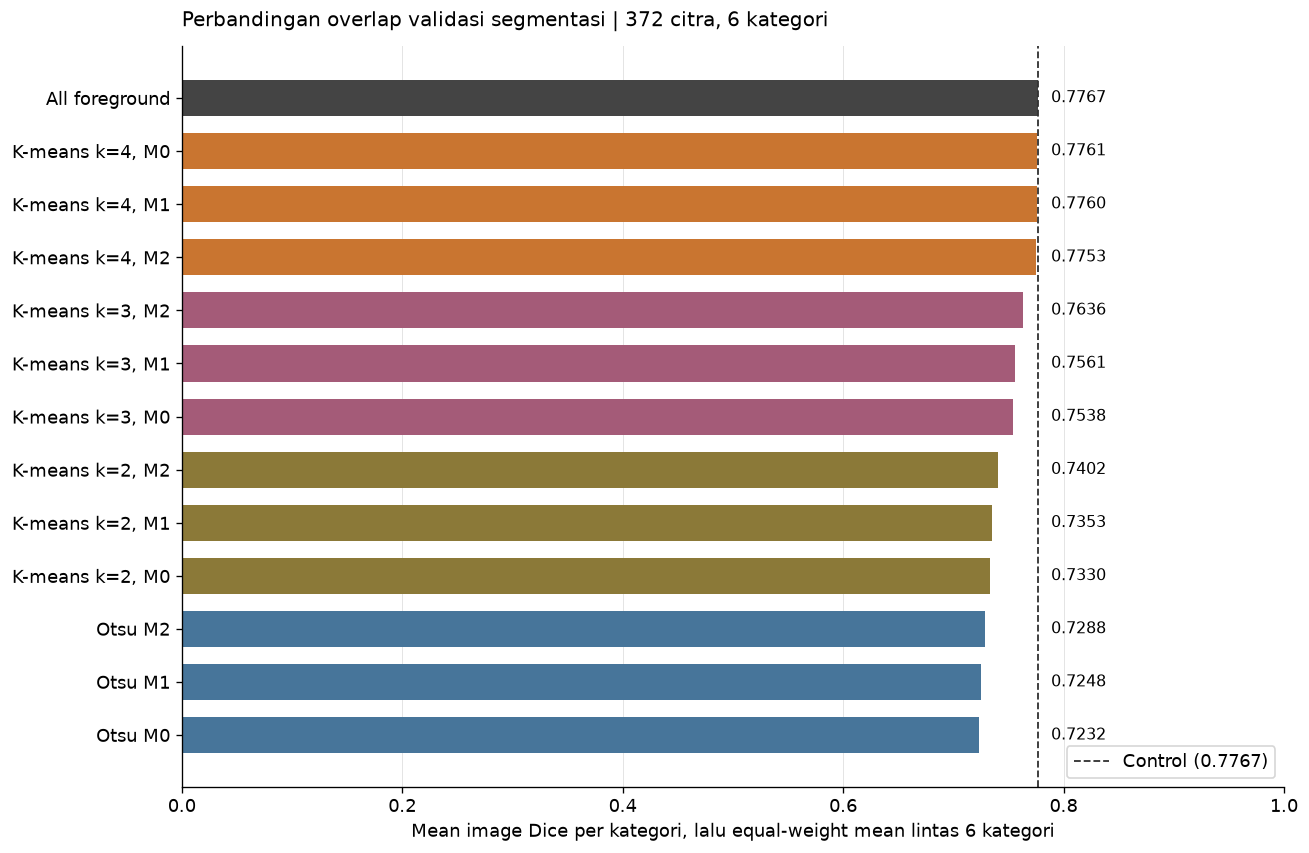

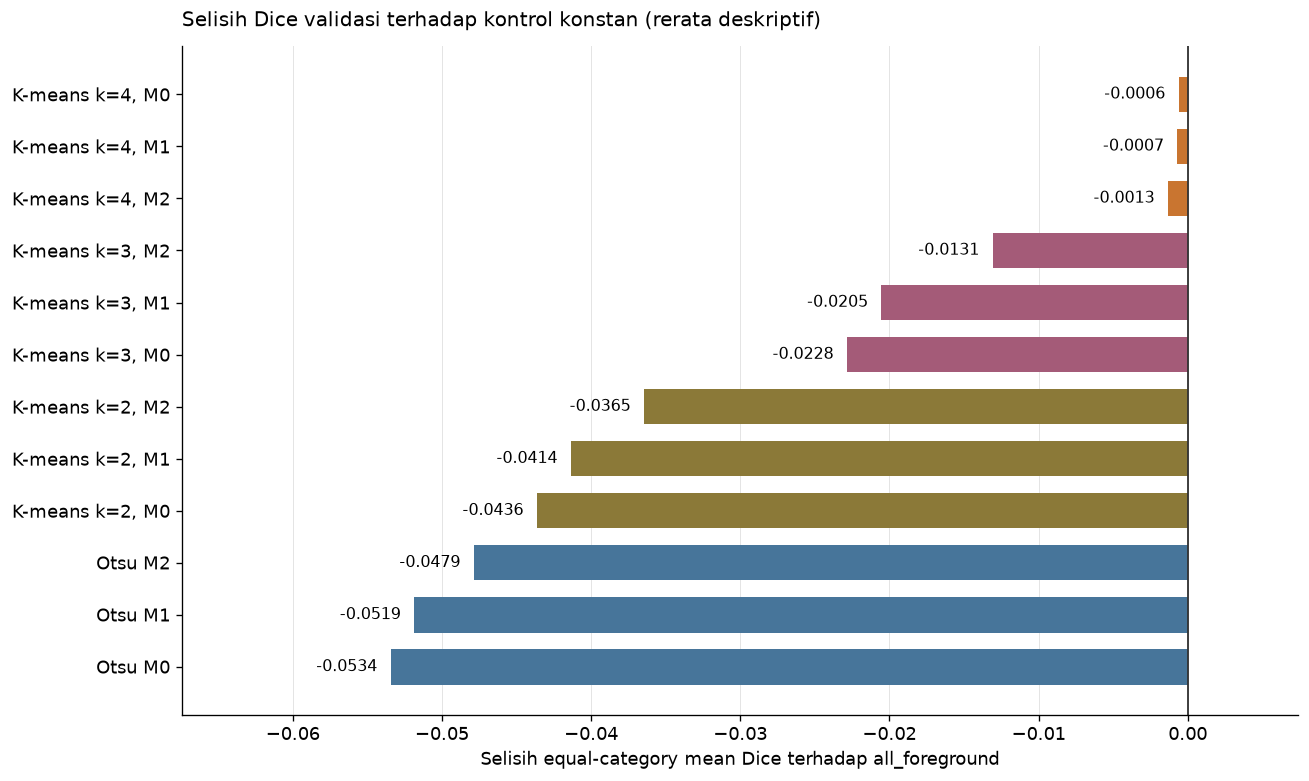

**Interpretasi hasil.** Kandidat *image-dependent* tertinggi adalah **K-means k=4, M0** (`Dice = 0.7761`, `IoU = 0.6427`), berada **0.0006 di bawah** kontrol `all_foreground` (`0.7767`). Varian morfologi `k4_M1` (`0.7760`) sangat dekat namun tidak melampaui `k4_M0`, sehingga sesuai aturan parismoni `k4_M0` menjadi kandidat utama.

In [4]:
family_colors = {
    "otsu": "#47759A",
    "k2": "#8B7938",
    "k3": "#A45B78",
    "k4": "#C97530",
    "all": "#444444",
}

def _method_color(method_id: str) -> str:
    return family_colors["all" if method_id == "all_foreground" else method_id.split("_")[0]]

ordered = summary.sort_values("mean_category_dice", ascending=True)
fig, ax = plt.subplots(figsize=(10.8, 7.0), layout="constrained")
y_pos = np.arange(len(ordered))
ax.barh(y_pos, ordered["mean_category_dice"], color=[_method_color(m) for m in ordered.index], height=0.68)
ax.set_yticks(y_pos, [method_label(m) for m in ordered.index])
control_dice = float(summary.loc["all_foreground", "mean_category_dice"])
for pos, val in zip(y_pos, ordered["mean_category_dice"]):
    ax.text(max(float(val), control_dice) + 0.012, pos, f"{val:.4f}", va="center", fontsize=9.8)
ax.axvline(control_dice, color="#333333", linewidth=1.1, linestyle="--", label=f"Control ({control_dice:.4f})")
ax.set_xlim(0.0, 1.0)
ax.set_xlabel("Mean image Dice per kategori, lalu equal-weight mean lintas 6 kategori")
ax.set_title("Perbandingan overlap validasi segmentasi | 372 citra, 6 kategori", loc="left", pad=12)
ax.grid(axis="x", color="#E4E4E4", linewidth=0.6)
ax.legend(loc="lower right", frameon=True)
finish_figure(
    fig,
    export_path=(ROOT / "reports/figures/segmentation_validation_dice.png") if EXPORT_FIGURES else None,
)

delta = summary.drop(index="all_foreground").sort_values("delta_dice_vs_control")
fig_d, ax_d = plt.subplots(figsize=(10.8, 6.4), layout="constrained")
y_d = np.arange(len(delta))
ax_d.barh(y_d, delta["delta_dice_vs_control"], color=[_method_color(m) for m in delta.index], height=0.68)
ax_d.set_yticks(y_d, [method_label(m) for m in delta.index])
for pos, val in zip(y_d, delta["delta_dice_vs_control"]):
    offset = -0.0009 if val < 0 else 0.0009
    ax_d.text(
        float(val) + offset,
        pos,
        f"{val:+.4f}",
        va="center",
        ha="right" if val < 0 else "left",
        fontsize=9.8,
    )
ax_d.axvline(0.0, color="#333333", linewidth=1.1)
ax_d.set_xlim(
    min(float(delta["delta_dice_vs_control"].min()) - 0.014, -0.01),
    max(float(delta["delta_dice_vs_control"].max()) + 0.008, 0.006),
)
ax_d.set_xlabel("Selisih equal-category mean Dice terhadap all_foreground")
ax_d.set_title("Selisih Dice validasi terhadap kontrol konstan (rerata deskriptif)", loc="left", pad=12)
ax_d.grid(axis="x", color="#E4E4E4", linewidth=0.6)
finish_figure(
    fig_d,
    export_path=(ROOT / "reports/figures/segmentation_validation_delta.png") if EXPORT_FIGURES else None,
)

best_row = summary.loc[best_candidate]
delta_best = float(best_row["delta_dice_vs_control"])
posisi = "di atas" if delta_best > 0 else "di bawah" if delta_best < 0 else "sama dengan"
display(
    Markdown(
        f"**Interpretasi hasil.** Kandidat *image-dependent* tertinggi adalah **{method_label(best_candidate)}** "
        f"(`Dice = {best_row['mean_category_dice']:.4f}`, `IoU = {best_row['mean_category_iou']:.4f}`), "
        f"berada **{abs(delta_best):.4f} {posisi}** kontrol `all_foreground` (`0.7767`). "
        "Varian morfologi `k4_M1` (`0.7760`) sangat dekat namun tidak melampaui `k4_M0`, sehingga sesuai aturan "
        "parismoni `k4_M0` menjadi kandidat utama."
    )
)

## 4. Tumpang tindih per kategori diagnostik

Setiap sel menampilkan rerata Dice citra di dalam satu kategori. Proyek memakai satu konfigurasi global per metode (tidak memilih model berdasarkan label kategori citra).

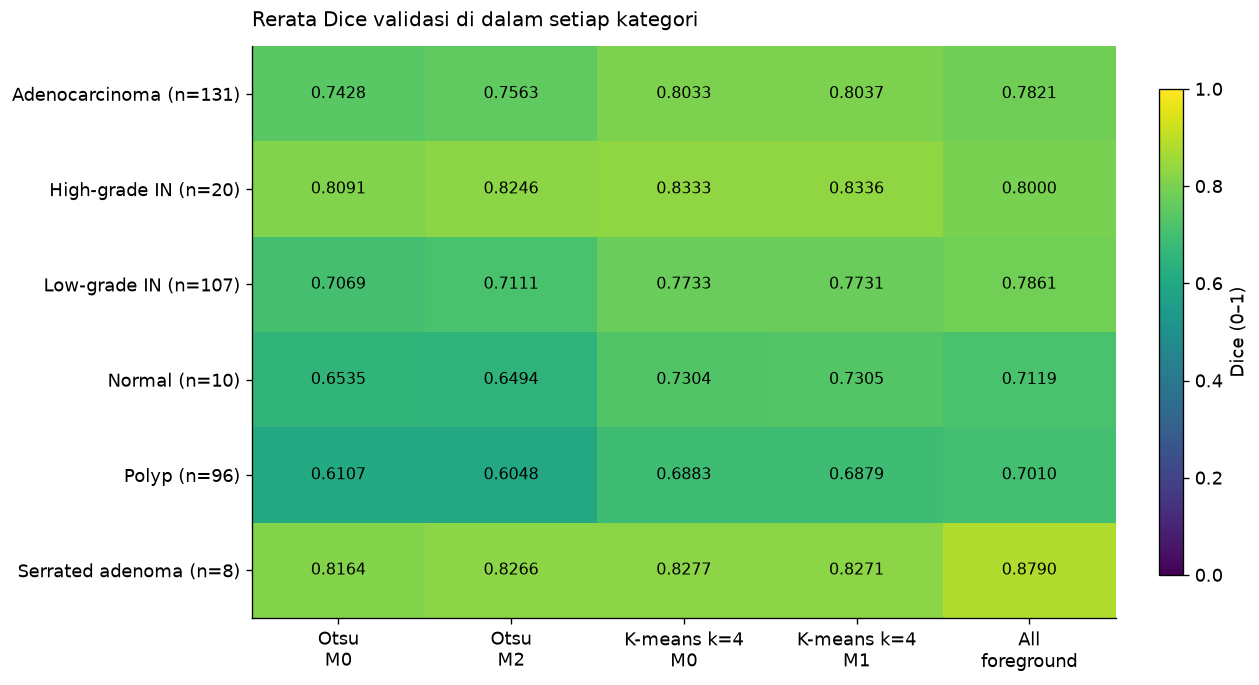

In [5]:
selected_methods = list(selected.values())
matrix = category_scores["dice"].unstack("method").reindex(
    index=list(EXPECTED_CATEGORIES),
    columns=selected_methods,
)

fig_hm, ax_hm = plt.subplots(figsize=(10.4, 5.6), layout="constrained")
hm = ax_hm.imshow(matrix.to_numpy(), cmap="viridis", vmin=0.0, vmax=1.0, aspect="auto")
ax_hm.set_xticks(
    np.arange(len(selected_methods)),
    [
        "Otsu\nM0",
        "Otsu\n" + selected["Processed Otsu"].split("_")[-1],
        method_label(selected["Raw K-means"]).replace(", ", "\n"),
        method_label(selected["Processed K-means"]).replace(", ", "\n"),
        "All\nforeground",
    ],
)
ax_hm.set_yticks(
    np.arange(len(EXPECTED_CATEGORIES)),
    [f"{cat} (n={int(cohort_table.loc[cat, 'validation_images'])})" for cat in EXPECTED_CATEGORIES],
)
for r_idx in range(len(EXPECTED_CATEGORIES)):
    for c_idx in range(len(selected_methods)):
        val = float(matrix.iloc[r_idx, c_idx])
        ax_hm.text(
            c_idx,
            r_idx,
            f"{val:.4f}",
            ha="center",
            va="center",
            color="black" if val >= 0.60 else "white",
            fontsize=9.8,
        )
ax_hm.set_title("Rerata Dice validasi di dalam setiap kategori", loc="left", pad=12)
fig_hm.colorbar(hm, ax=ax_hm, label="Dice (0–1)", shrink=0.85)
finish_figure(
    fig_hm,
    export_path=(ROOT / "reports/figures/segmentation_validation_category_heatmap.png") if EXPORT_FIGURES else None,
)

## 5. Distribusi *reference foreground coverage* pada kohort validasi

Fraksi cakupan *foreground* referensi menjelaskan mengapa kontrol `all_foreground` tampak kompetitif secara rata-rata: pada kategori seperti `Normal`, `High-grade IN`, dan `Serrated adenoma`, area anotasi referensi mencakup porsi besar bidang citra.

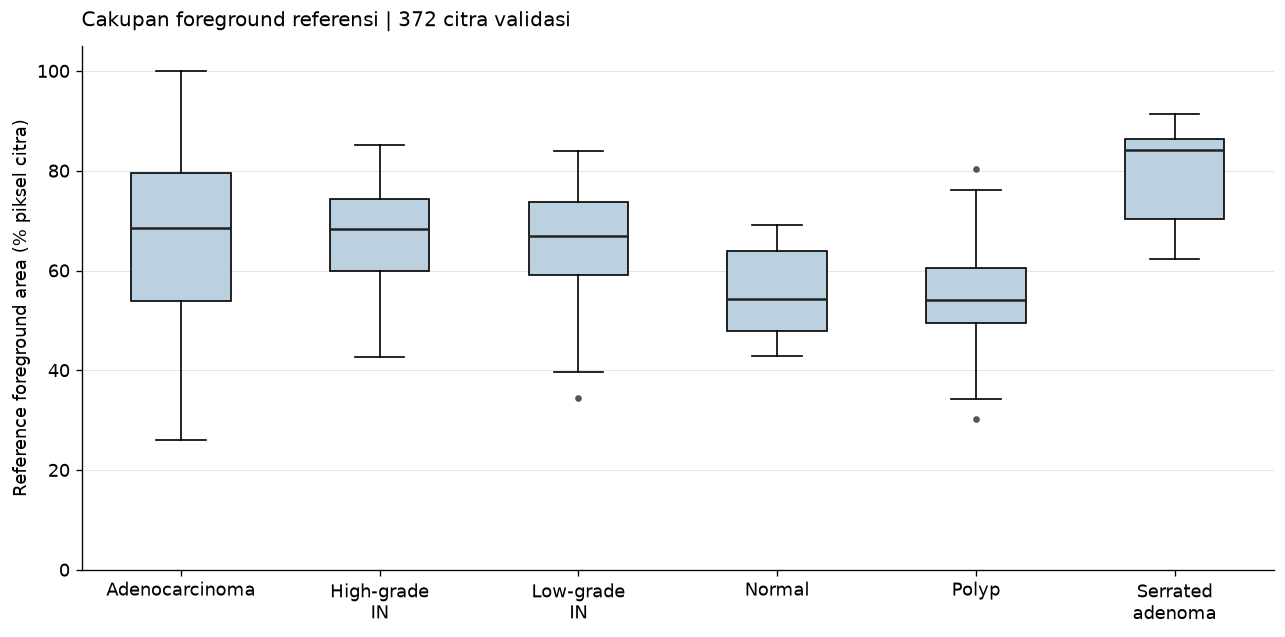

,count,min,median,mean,max
category,,,,,
Adenocarcinoma,131,26.10,68.60,66.46,100.00
High-grade IN,20,42.63,68.44,67.29,85.24
Low-grade IN,107,34.42,66.92,65.44,84.04
Normal,10,42.87,54.40,55.77,69.22
Polyp,96,30.26,54.15,54.64,80.39
Serrated adenoma,8,62.35,84.15,79.04,91.38


In [6]:
coverage = (
    results.loc[results["method"].eq("all_foreground"), ["sample_id", "category", "reference_foreground_fraction"]]
    .assign(reference_fg_pct=lambda df: 100.0 * df["reference_foreground_fraction"])
)

fig_cov, ax_cov = plt.subplots(figsize=(10.6, 5.2), layout="constrained")
cov_values = [
    coverage.loc[coverage["category"].eq(cat), "reference_fg_pct"].to_numpy()
    for cat in EXPECTED_CATEGORIES
]
bp = ax_cov.boxplot(
    cov_values,
    tick_labels=[cat.replace(" ", "\n") for cat in EXPECTED_CATEGORIES],
    patch_artist=True,
    medianprops={"color": "#222222", "linewidth": 1.5},
    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "#555555", "markeredgecolor": "#555555"},
)
for patch in bp["boxes"]:
    patch.set_facecolor("#BCD1E0")
ax_cov.set_ylim(0, 105)
ax_cov.set_ylabel("Reference foreground area (% piksel citra)")
ax_cov.set_title("Cakupan foreground referensi | 372 citra validasi", loc="left", pad=12)
ax_cov.grid(axis="y", color="#E4E4E4", linewidth=0.6)
finish_figure(
    fig_cov,
    export_path=(ROOT / "reports/figures/validation_reference_foreground_coverage.png") if EXPORT_FIGURES else None,
)

display(
    coverage.groupby("category", observed=True)["reference_fg_pct"]
    .agg(["count", "min", "median", "mean", "max"])
    .reindex(list(EXPECTED_CATEGORIES))
    .round(2)
)

## 6. Provenance artefak dan garis keturunan *helper* (`utf8-lf-v1`)

Metadata *run* historis mencatat `SHA-256` *raw-byte* `CRLF` untuk `kmeans_prediction.py` dan `postprocessing.py`. Melalui `configs/provenance_migration.json`, garis keturunan kedua *helper* tersebut diverifikasi secara eksplisit terhadap modul terpusat `src/ebhi_dip/segmentation.py` menggunakan skema portabel `utf8-lf-v1`, sementara `split_manifest.csv` dan JSON model tetap diverifikasi secara *raw-byte*.

In [7]:
run_meta = json.loads(source_files["run"].read_text(encoding="utf-8"))
prov_checks = pd.DataFrame(
    [
        verify_helper_provenance(ROOT, "kmeans_prediction", run_meta["prediction_helper_sha256"]),
        verify_helper_provenance(ROOT, "postprocessing", run_meta["postprocessing_helper_sha256"]),
    ]
)
display(prov_checks)

artifact_inventory = pd.DataFrame(
    [
        {
            "artefak": path.relative_to(ROOT).as_posix(),
            "bytes": path.stat().st_size,
            "sha256_prefix": input_hashes_before[name][:20],
        }
        for name, path in source_files.items()
    ]
)
display(artifact_inventory)

,role,recorded_sha256,legacy_path,legacy_status,legacy_verified_utf8_lf_v1,migrated_module,migrated_function,migrated_utf8_lf_v1,verified
0,kmeans_prediction,42a0a3a5c84689f7f3f221d80e27a28ee3949e4d3e3a64...,kmeans_prediction.py,retired_to_package,d66c08b08240eb2ad9e19516b0d0d29f70b10f68f621fa...,src/ebhi_dip/segmentation.py,ebhi_dip.segmentation.nearest_clusters,128cb8c94b45cf88a717754fc3d96116112f09b761d518...,True
1,postprocessing,b83e549480fec3f8373eb7d95db6a8194d53795d916117...,postprocessing.py,retired_to_package,767318f20709eb93acd5c2c5c5f011ca9de9710e2976c0...,src/ebhi_dip/segmentation.py,ebhi_dip.segmentation.morphology_variants,128cb8c94b45cf88a717754fc3d96116112f09b761d518...,True


,artefak,bytes,sha256_prefix
0,data/metadata/split_manifest.csv,575716,ceeba8e282f77cdb78a9
1,data/metadata/split_manifest.sha256,86,b71ce04e201fa038cd82
2,results/otsu_morph_val.csv,81575,17f24293a33b1fefe78a
3,results/kmeans_morph_val.csv,530758,8a30172c8d2d90b453e7
4,results/kmeans_morph_val_run.json,1066,5ecd034b88d84ecab74b
5,configs/otsu_raw.json,466,dcd8b0867f50f10912fc
6,configs/provenance_migration.json,2382,422b507b60791415abbf
7,models/kmeans_lab_k2_mapped.json,2390,026a125a21a32bfef19f
8,models/kmeans_lab_k3_mapped.json,2549,d50bcf44f4ec87b69549
9,models/kmeans_lab_k4_mapped.json,2715,0531165e8f29433738e8


## Kesimpulan dan langkah analisis selanjutnya

- **Temuan utama:** `k4_M0` adalah kandidat *image-dependent* terbaik pada `val` (`Dice = 0.7761`), melampaui `otsu_M0` (`0.7232`) dan `otsu_M2` (`0.7288`), tetapi belum melampaui rerata kontrol `all_foreground` (`0.7767`).
- **Mengapa perlu analisis per citra:** rerata kategori menyembunyikan variasi besar antar sampel. Notebook `05b_segmentation_case_analysis.ipynb` memeriksa pada citra mana `otsu_M0` maupun `k4_M0` unggul atau gagal melalui perbandingan berpasangan, *error overlay*, dan histogram.

In [8]:
input_hashes_after = {name: sha256_bytes(path) for name, path in source_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak input berubah saat notebook dijalankan."
assert set(results["sample_id"]) == set(validation["sample_id"])
print("Selesai: 13 metode, 372 citra validasi, 4 visualisasi; seluruh artefak input tetap identik.")

Selesai: 13 metode, 372 citra validasi, 4 visualisasi; seluruh artefak input tetap identik.
